# 17 — K-Nearest Neighbours (KNN)

**Algorithm:** KNeighborsClassifier (cosine distance, k=5)  
**Features:** TF-IDF (50K) — subsampled to 30K for tractable search  
KNN classifies by majority vote among the k nearest training points. Cosine similarity is the natural distance for TF-IDF vectors. The k vs accuracy plot shows how neighbourhood size affects bias-variance trade-off.

In [1]:
import os, sys, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), '..')))
from utils import (setup_paths, evaluate_and_print, plot_confusion_matrix,
                   plot_roc_curve, plot_pr_curve)
from sklearn.metrics import accuracy_score
BASE_DIR, FIGURES_DIR = setup_paths()

In [2]:
from preprocess import load_all_datasets, get_train_test_split
df = load_all_datasets()
X_train, X_test, y_train, y_test = get_train_test_split(df)
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf = TfidfVectorizer(max_features=50000, ngram_range=(1,2), sublinear_tf=True, min_df=2, max_df=0.95)
X_tr_full = tfidf.fit_transform(X_train)
X_te = tfidf.transform(X_test)

# Subsample training set (KNN is O(n) at inference)
KNN_SAMPLE = 30000
np.random.seed(42)
knn_idx = np.random.choice(X_tr_full.shape[0], min(KNN_SAMPLE, X_tr_full.shape[0]), replace=False)
X_tr = X_tr_full[knn_idx]
y_tr = y_train[knn_idx]
print(f'KNN train subset: {X_tr.shape[0]:,}  |  Test: {len(X_test):,}')


  LOADING ALL DATASETS
  [1/5] Loading ISOT Dataset...
      Loaded 44,898 records  (Fake=23,481  Real=21,417)
  [2/5] Loading FakeNewsNet Dataset...
      Loaded 23,196 records  (Fake=5,755  Real=17,441)
  [3/5] Loading LIAR Dataset...
      Loaded 12,791 records  (Fake=5,657  Real=7,134)
  [4/5] Loading MultiFC Dataset...
      Loaded 31,921 records  (Fake=13,980  Real=17,941)
  [5/5] Loading BuzzFeed Dataset...
      Loaded 2,282 records  (Fake=613  Real=1,669)

  Combined total   : 115,088 records
  Fake (0)         : 49,486
  Real (1)         : 65,602

  Cleaning text...
  After clean+dedup: 104,521 records

  Source distribution:
source
ISOT           38826
MultiFC        31919
FakeNewsNet    21046
LIAR           12726
BuzzFeed           4
KNN train subset: 30,000  |  Test: 20,905


## Model Training

In [3]:
from sklearn.neighbors import KNeighborsClassifier
MODEL_NAME = 'KNN'
model = KNeighborsClassifier(n_neighbors=5, n_jobs=-1, metric='cosine')
t0 = time.time()
model.fit(X_tr, y_tr)
train_time = time.time() - t0
print(f'Fitting completed in {train_time:.2f}s')
metrics, y_pred, y_prob = evaluate_and_print(model, X_te, y_test, MODEL_NAME, train_time)

Fitting completed in 0.02s

  KNN — Evaluation Results
  Accuracy          : 0.7515
  Precision         : 0.7496
  Recall            : 0.7515
  F1 Score          : 0.7473
  AUC-ROC           : 0.8243
  Train Time (s)    : 0.02s

              precision    recall  f1-score   support

    Fake (0)       0.73      0.62      0.67      8532
    Real (1)       0.76      0.84      0.80     12373

    accuracy                           0.75     20905
   macro avg       0.75      0.73      0.74     20905
weighted avg       0.75      0.75      0.75     20905



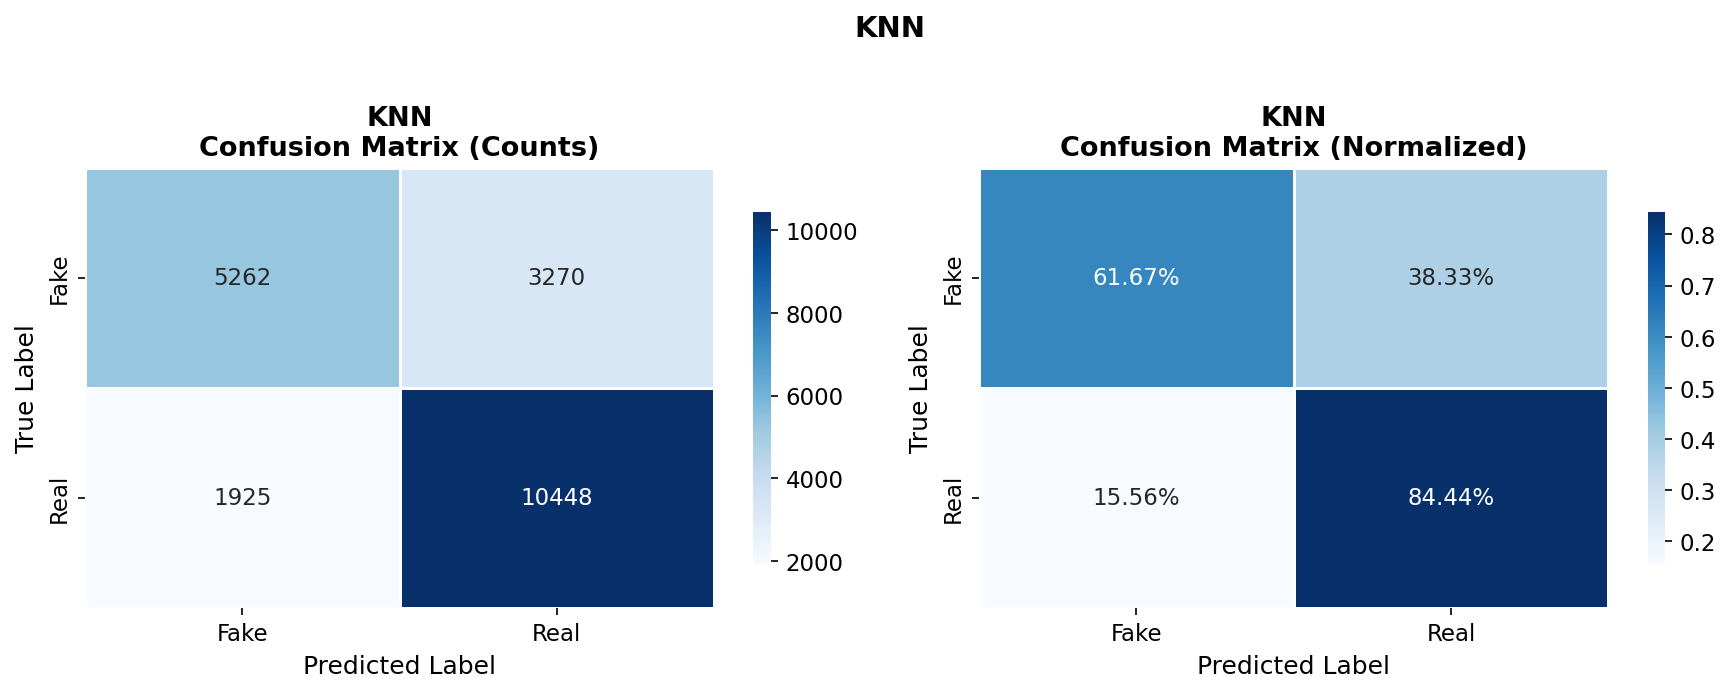

In [4]:
plot_confusion_matrix(y_test, y_pred, MODEL_NAME, FIGURES_DIR)

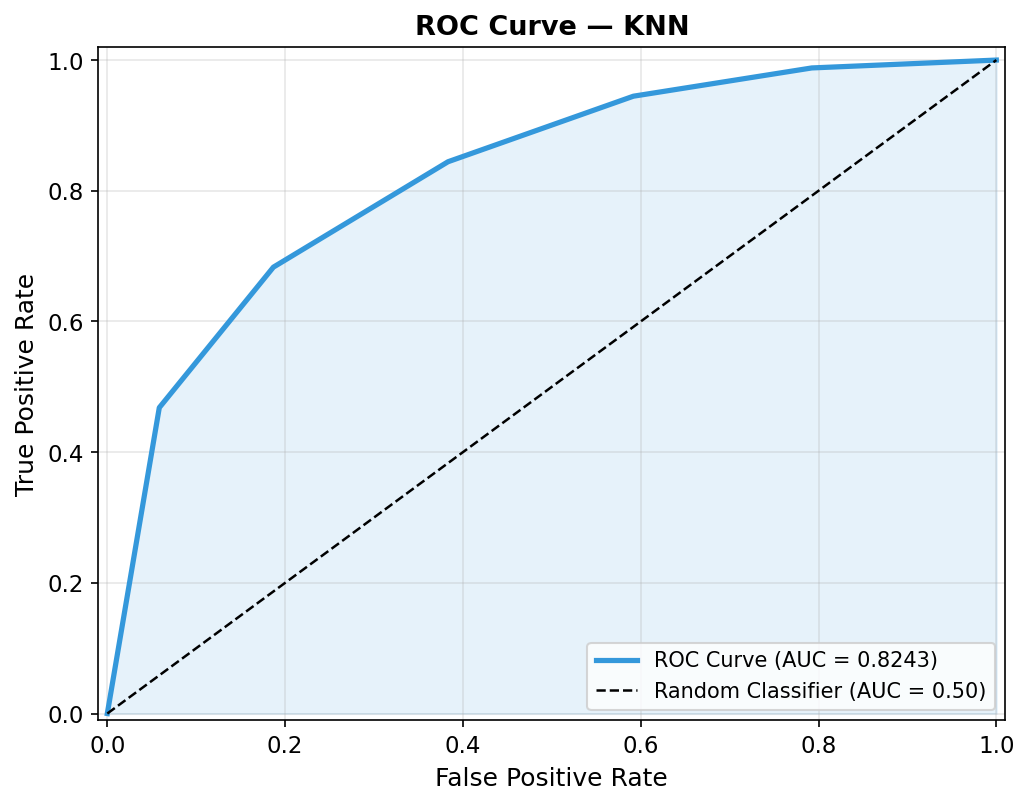

In [5]:
plot_roc_curve(y_test, y_prob, MODEL_NAME, FIGURES_DIR)

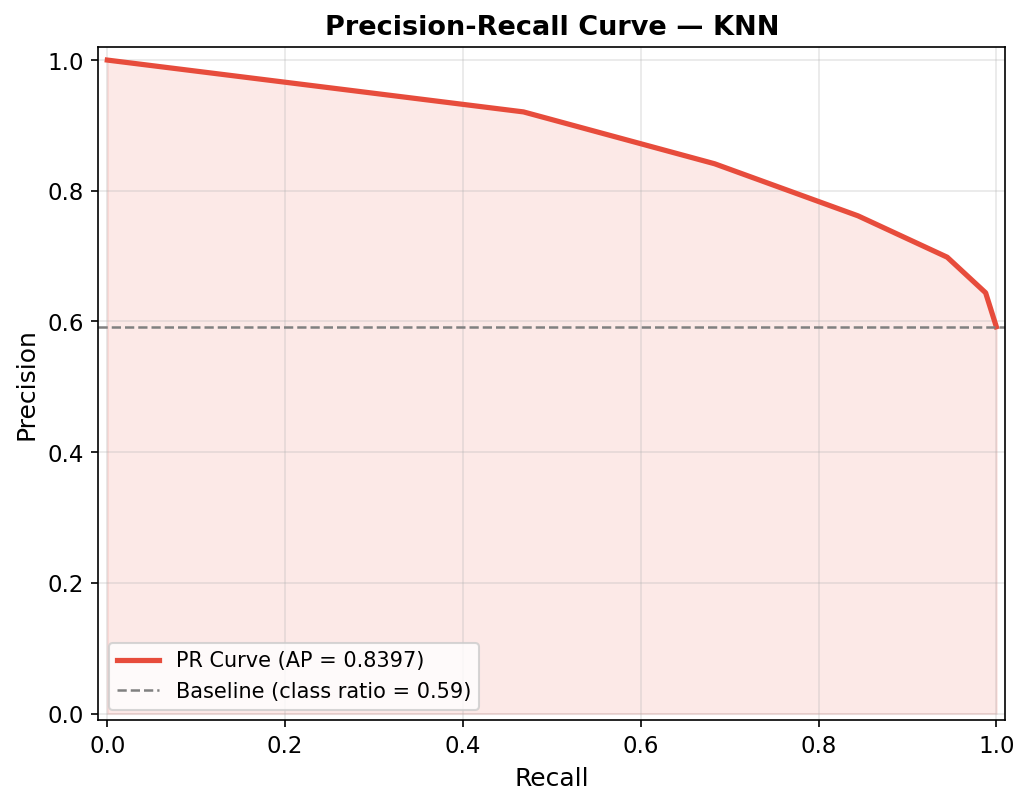

In [6]:
plot_pr_curve(y_test, y_prob, MODEL_NAME, FIGURES_DIR)

## Convergence: k vs Accuracy

  k= 1: Train=1.0000  Test=0.7016
  k= 3: Train=0.8542  Test=0.7403
  k= 5: Train=0.8338  Test=0.7515
  k= 7: Train=0.8231  Test=0.7607
  k=10: Train=0.8195  Test=0.7714
  k=15: Train=0.8085  Test=0.7723
  k=20: Train=0.8086  Test=0.7777
  k=30: Train=0.8032  Test=0.7788
  k=50: Train=0.8012  Test=0.7833


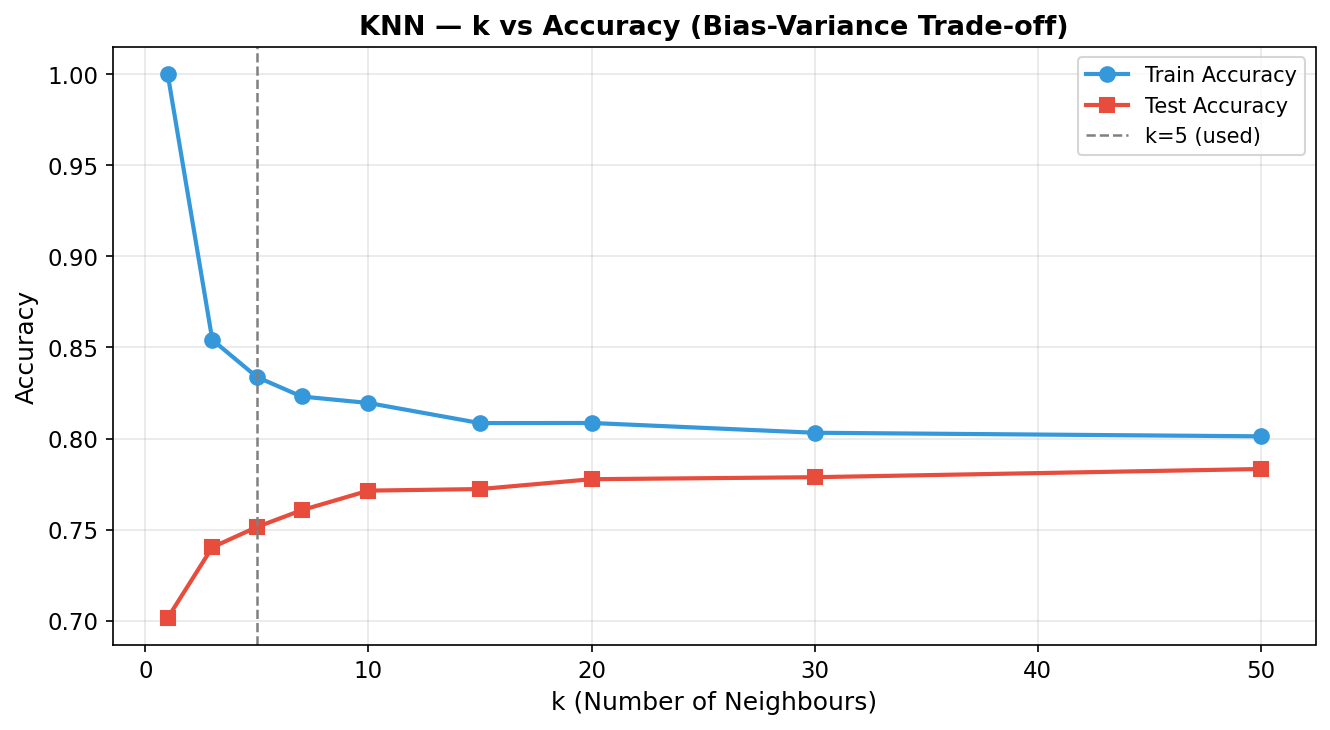

In [7]:
k_values = [1, 3, 5, 7, 10, 15, 20, 30, 50]
tr_accs, te_accs = [], []
for k in k_values:
    m = KNeighborsClassifier(n_neighbors=k, n_jobs=-1, metric='cosine')
    m.fit(X_tr, y_tr)
    tr_accs.append(accuracy_score(y_tr, m.predict(X_tr)))
    te_accs.append(accuracy_score(y_test, m.predict(X_te)))
    print(f'  k={k:>2}: Train={tr_accs[-1]:.4f}  Test={te_accs[-1]:.4f}')

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(k_values, tr_accs, 'o-', color='#3498db', lw=2, ms=7, label='Train Accuracy')
ax.plot(k_values, te_accs, 's-', color='#e74c3c', lw=2, ms=7, label='Test Accuracy')
ax.axvline(5, color='grey', linestyle='--', lw=1.2, label='k=5 (used)')
ax.set_xlabel('k (Number of Neighbours)')
ax.set_ylabel('Accuracy')
ax.set_title('KNN — k vs Accuracy (Bias-Variance Trade-off)')
ax.legend(fontsize=10); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'knn_k_vs_accuracy.png'), dpi=150, bbox_inches='tight')
plt.show()